In [ ]:
#Import the main libraries used throughout the analysis
!pip install gensim
import pandas as pd
import numpy as np
import re
import html
import unicodedata
import warnings

#Visualisation libraries
import matplotlib.pyplot as plt
import seaborn as sns

#NLP and machine-learning libaries
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from gensim import corpora
from gensim.models.coherencemodel import CoherenceModel

#NLTK
from nltk.stem import SnowballStemmer

#word cloud
from wordcloud import WordCloud

#ignore unnecessary warning messages so the output is easier to read
warnings.filterwarnings('ignore')

#display plots directly inside google colab
%matplotlib inline

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 41.4 MB/s eta 0:00:00


In [ ]:
#Load the dataset
tweets = pd.read_csv('tweets.csv')

#display the size of the dataset
print("Number of rows:", tweets.shape[0])
print("Number of columns:", tweets.shape[1])

#display the first 5 records
tweets.head()

Number of rows: 50000
Number of columns: 19


,Tweet Id,Tweet URL,Tweet Posted Time,Tweet Content,Tweet Type,Client,Retweets Received,Likes Received,Tweet Location,Tweet Language,User Id,Name,Username,User Bio,Verified or Non-Verified,Profile URL,User Followers,User Following,User Account Creation Date
0,"""1570926731019825152""",https://twitter.com/_MKKX_7/status/15709267310...,17 Sep 2022 00:04:53,"""أدعم التغريدات وفضّلها وأنشرها🙏🏻\n\n🚨سلسلة |#...",ReTweet,"""Twitter for Android""",0,0,"""""",Arabic,"""1138927555946471424""","""ندى الورد 🇸🇦💚""",_MKKX_7,"""إن تحققت أمانينا فالحمد لله و إن تأخرت فهي حت...",Non-Verified,https://twitter.com/_MKKX_7,169.0,4999.0,12-Jun-2019 21:54:24
1,"""1570926731183423488""",https://twitter.com/hungblct/status/1570926731...,17 Sep 2022 00:04:53,"""💧 Unidef Airdrop 💧\n\n🏆 Task: ➕ $9 ...",ReTweet,"""Twitter for Android""",0,0,"""""",English,"""1381649113943482370""","""Nguyễn Hưng""",hungblct,"""Thánh 😇""",Non-Verified,https://twitter.com/hungblct,38.0,3354.0,12-Apr-2021 16:43:22
2,"""1570926713571520513""",https://twitter.com/plusendless/status/1570926...,17 Sep 2022 00:04:49,"""Etheruem has officially merged and moved towa...",ReTweet,"""Twitter for Android""",0,0,"""""",English,"""1381898326728175616""","""Mischa Markus""",plusendless,"""#Bitcoin value = ∞\nsupply limited to 21 mill...",Non-Verified,https://twitter.com/plusendless,128.0,432.0,13-Apr-2021 09:13:54
3,"""1570926715228295175""",https://twitter.com/bengali_tech/status/157092...,17 Sep 2022 00:04:49,"""New airdrop: Kingdomverse (USDT)\nTotal Rewar...",ReTweet,"""Twitter for Android""",0,0,"""""",English,"""1230524903918575617""","""𝗠𝗔 𝗢𝗳𝗳𝗶𝗰𝗶𝗮𝗹 𝗘𝗮𝗿𝗻𝗶𝗻𝗴""",bengali_tech,"""I am youtuber.Please visit my channel..My cha...",Non-Verified,https://twitter.com/bengali_tech,37.0,2817.0,20-Feb-2020 16:09:46
4,"""1570926708165050370""",https://twitter.com/Maheshishere4/status/15709...,17 Sep 2022 00:04:48,"""Bitcoin price just went down by $23! Current ...",Tweet,"""Nft Data Bot""",0,1,"""""",English,"""1557406769957449728""","""nft mahesh""",Maheshishere4,"""Crypto & NFT Degen • #NFT Marketing / Advisor...",Non-Verified,https://twitter.com/Maheshishere4,308.0,749.0,10-Aug-2022 16:41:45


#1. Data Understanding and Audit

In [ ]:
from sqlalchemy import column
#display all variable names in the dataset
print("Variable names in the dataset:")
for number in enumerate(tweets.columns, start=1):
  print(f"{number}.{column}")

Variable names in the dataset:
(1, 'Tweet Id').<function column at 0x7e89c2ea2ac0>
(2, 'Tweet URL').<function column at 0x7e89c2ea2ac0>
(3, 'Tweet Posted Time').<function column at 0x7e89c2ea2ac0>
(4, 'Tweet Content').<function column at 0x7e89c2ea2ac0>
(5, 'Tweet Type').<function column at 0x7e89c2ea2ac0>
(6, 'Client').<function column at 0x7e89c2ea2ac0>
(7, 'Retweets Received').<function column at 0x7e89c2ea2ac0>
(8, 'Likes Received').<function column at 0x7e89c2ea2ac0>
(9, 'Tweet Location').<function column at 0x7e89c2ea2ac0>
(10, 'Tweet Language').<function column at 0x7e89c2ea2ac0>
(11, 'User  Id').<function column at 0x7e89c2ea2ac0>
(12, 'Name').<function column at 0x7e89c2ea2ac0>
(13, 'Username').<function column at 0x7e89c2ea2ac0>
(14, 'User Bio').<function column at 0x7e89c2ea2ac0>
(15, 'Verified or Non-Verified').<function column at 0x7e89c2ea2ac0>
(16, 'Profile URL').<function column at 0x7e89c2ea2ac0>
(17, 'User Followers').<function column at 0x7e89c2ea2ac0>
(18, 'User Fol

In [ ]:
#audit table showing the structure of every variable
audit_table = pd.DataFrame({
    "Variables": tweets.columns,
    "Data Type": tweets.dtypes.astype(str).values,
    "Missing Values": tweets.isna().sum().values,
    "Unique values": tweets.nunique().values
})

audit_table

,Variables,Data Type,Missing Values,Unique values
0,Tweet Id,object,0,50000
1,Tweet URL,object,0,50000
2,Tweet Posted Time,object,0,19969
3,Tweet Content,object,0,19845
4,Tweet Type,object,0,3
5,Client,object,0,661
6,Retweets Received,int64,0,111
7,Likes Received,int64,0,232
8,Tweet Location,object,0,57
9,Tweet Language,object,564,46


In [ ]:
#display general informatuion about numerical variables.
tweets.describe().T

,count,mean,std,min,25%,50%,75%,max
Retweets Received,50000.0,0.458200,14.184372,0.0,0.0,0.0,0.0,1682.0
Likes Received,50000.0,1.883920,37.086350,0.0,0.0,0.0,0.0,3208.0
User Followers,49999.0,3979.396308,42521.555288,0.0,30.0,128.0,522.5,2631968.0
User Following,49999.0,1136.852797,3643.131073,0.0,54.0,284.0,1088.0,327695.0


###Important Variables
Tweet Posted Time

Tweet Content

Tweet Type

Tweet Language

Retweets Received

Likes Received

In [ ]:
#Which tweets to model
#count tweets by detected language
language_counts = tweets["Tweet Language"].value_counts(dropna=False)
print(language_counts.head(15))

Tweet Language
English       33515
Turkish        8309
Arabic         2592
Spanish        1309
qme            1142
NaN             564
French          500
Japanese        389
Portuguese      292
German          207
qht             205
Italian         182
in              119
art              84
Czech            63
Name: count, dtype: int64


In [ ]:
#examine the different types of tweets.
print(tweets["Tweet Type"].value_counts())

Tweet Type
ReTweet    33219
Tweet      11765
Reply       5016
Name: count, dtype: int64


###The dataset has Tweet, ReTweet, and Reply

Repeated retweets can cause the same message to have disproportionate influence on the topics. Therefore, we exclude records of ReTweets and retain normal tweets and replies because they still represent converstions surrounding Bitcoin.

In [ ]:
#keep Emglish tweets and exclude records explicitly marked as retweets
model_data = tweets[(tweets["Tweet Language"] == "English") &
 (tweets["Tweet Type"] != "ReTweet")
 ].copy()

print("Rows after language and retweet filtering:", len(model_data))


Rows after language and retweet filtering: 12990


In [ ]:
#convert the tweet timestamp from text into pandas datetime format
model_data["datetime"] = pd.to_datetime(
    model_data["Tweet Posted Time"],
    errors="coerce"
)

#check whether any dated could not be converted
print("Invalid dates:", model_data["datetime"].isna().sum())

#diaplay a few converted dates
model_data[["Tweet Posted Time", "datetime"]].head()

Invalid dates: 0


,Tweet Posted Time,datetime
4,17 Sep 2022 00:04:48,2022-09-17 00:04:48
7,17 Sep 2022 00:04:46,2022-09-17 00:04:46
8,17 Sep 2022 00:04:46,2022-09-17 00:04:46
13,17 Sep 2022 00:04:42,2022-09-17 00:04:42
17,17 Sep 2022 00:04:30,2022-09-17 00:04:30


In [ ]:
#Remove all missing and duplicate tweets

#remove rows where the tweet text is missing
model_data = model_data.dropna(subset=["Tweet Content"])

#remove rows where the date could not be converted
model_data = model_data.dropna(subset=["datetime"])

#remove exact duplicate tweet text
#this prevents identical messages from receiving excessive influence
before_duplicates = len(model_data)

model_data = model_data.drop_duplicates(subset=["Tweet Content"])

after_duplicates = len(model_data)

print("Duplicates removed:", before_duplicates - after_duplicates)
print("Remaining tweets:", after_duplicates)

Duplicates removed: 937
Remaining tweets: 12053


##Audit Table

In [ ]:
audit_table = pd.DataFrame({

    "Original variable name": [
        "Tweet Id",
        "Tweet URL",
        "Tweet Posted Time",
        "Tweet Content",
        "Tweet Type",
        "Client",
        "Retweets Received",
        "Likes Received",
        "Tweet Location",
        "Tweet Language",
        "User Id",
        "Name",
        "Username",
        "User Bio",
        "Verified or Non-Verified",
        "Profile URL",
        "User Followers",
        "User Following",
        "User Account Creation Date"
    ],

    "New variable name": [
        "Tweet Id",
        "Tweet URL",
        "datetime",
        "cleaned_text",
        "Tweet Type",
        "Client",
        "Retweets Received",
        "Likes Received",
        "Tweet Location",
        "Tweet Language",
        "User Id",
        "Name",
        "Username",
        "User Bio",
        "Verified or Non-Verified",
        "Profile URL",
        "User Followers",
        "User Following",
        "User Account Creation Date"
    ],

    "Original data type": [
        "Object",
        "Object",
        "Object",
        "Object",
        "Object",
        "Object",
        "Integer",
        "Integer",
        "Object",
        "Object",
        "Object",
        "Object",
        "Object",
        "Object",
        "Object",
        "Object",
        "Float",
        "Float",
        "Object"
    ],

    "New data type": [
        "Object",
        "Object",
        "Datetime",
        "Object",
        "Object",
        "Object",
        "Integer",
        "Integer",
        "Object",
        "Object",
        "Object",
        "Object",
        "Object",
        "Object",
        "Object",
        "Object",
        "Float",
        "Float",
        "Object"
    ],

    "Description / meaning": [
        "Unique identifier for each tweet.",
        "URL linking to the original tweet.",
        "Date and time when the tweet was posted.",
        "Original text of the tweet used for NLP analysis.",
        "Identifies whether the record is a tweet, retweet or reply.",
        "Application or client used to post the tweet.",
        "Number of times the tweet was retweeted.",
        "Number of likes received by the tweet.",
        "Location associated with the tweet.",
        "Language identified for the tweet.",
        "Unique identifier of the user.",
        "Display name of the user.",
        "Username of the account.",
        "Description provided in the user's profile.",
        "Indicates whether the account is verified.",
        "URL of the user's profile.",
        "Number of followers of the user.",
        "Number of accounts the user follows.",
        "Date on which the user's account was created."
    ]
})

audit_table

,Original variable name,New variable name,Original data type,New data type,Description / meaning
0,Tweet Id,Tweet Id,Object,Object,Unique identifier for each tweet.
1,Tweet URL,Tweet URL,Object,Object,URL linking to the original tweet.
2,Tweet Posted Time,datetime,Object,Datetime,Date and time when the tweet was posted.
3,Tweet Content,cleaned_text,Object,Object,Original text of the tweet used for NLP analysis.
4,Tweet Type,Tweet Type,Object,Object,"Identifies whether the record is a tweet, retw..."
5,Client,Client,Object,Object,Application or client used to post the tweet.
6,Retweets Received,Retweets Received,Integer,Integer,Number of times the tweet was retweeted.
7,Likes Received,Likes Received,Integer,Integer,Number of likes received by the tweet.
8,Tweet Location,Tweet Location,Object,Object,Location associated with the tweet.
9,Tweet Language,Tweet Language,Object,Object,Language identified for the tweet.


#2. Text Cleaning and PreProcessing

In [ ]:
#Install prontify detection package used to identify tweets containing clearly offencife language
!pip -q install better-profanity

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.1/46.1 kB 627.5 kB/s eta 0:00:00


In [ ]:
from better_profanity import profanity

#load the package's profaninty word list
profanity.load_censor_words()

#automated profanity dictionaries are not perfect. They can miss offensive or occasionally flag words incorrectly.
# Therefore, this step is an automated screening step rather than a perfect content-classification system.

###Creating the cleaning function
We kept words related to Bitcoin such as:

*   btc
*   bullish
*   mining
*   treading
*   price
*   volatility







In [ ]:
#English stop words supplied by scikit-learn
stop_words = set(ENGLISH_STOP_WORDS)

#Additional words that are usually technical leftovers from social media cleaning rather than meaningful topics
custom_stop_words = {
    "rt"
    "amp"
    "http"
    "https"
    "tco"
    "www"
}

stop_words.update(custom_stop_words)

#snowball stemmer reduces words to a common root
stemmer = SnowballStemmer("english")

def clean_tweet(text):

 #convert the value to a string and decode HTML entities such as &amp;.
 text = html.unescape(str(text))

 #remove web addresses because URLs
 text = re.sub(r"https?://\S+|www\.\S+", " ", text)

 #remove Twitter user mentions
 text = re.sub(r"@\w+", " ",text)

 #Remove the hashtag symbol but keep the word
 text = re.sub(r"#", "",text)

 #convert accented characters where possible
 text = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode("ascii")

 #convert everything to lowercase
 text = text.lower()

 #keep alphabetic characters and spaces only
 text = re.sub(r"[^a-z\s]", " ", text)

 #split the tweet into individual words
 tokens = text.split()

 cleaned_tokens =[]

 for word in tokens:
    #remove stop words and very short tokens
    if word in stop_words or len(word) <= 2:
      continue

    #stem the remaining word.
    stemmed_word = stemmer.stem(word)

    cleaned_tokens.append(stemmed_word)

  #join the processed tokens back into one document
 return " ".join(cleaned_tokens)

In [ ]:
#check each original tweet for offensive language
model_data["is_offensive"] = model_data["Tweet Content"].apply(
    profanity.contains_profanity
)

print(
    "Tweets flagged as potentially offensive:",
    model_data["is_offensive"].sum()
)

Tweets flagged as potentially offensive: 178


In [ ]:
#Remove all flagged tweets
#keep only tweets that were not flagged but the profanity detector
model_data = model_data[
    ~model_data["is_offensive"]
    ].copy()
#remove the temporary flag because it is no longer needed
model_data.drop(columns=["is_offensive"], inplace=True)

print("Tweets remaining:", len(model_data))

Tweets remaining: 11875


In [ ]:
#Clean the tweets

#Apply our cleaning fucntion to every tweet
model_data["cleaned_text"] = model_data["Tweet Content"].apply(
    clean_tweet
)

#remove tweets that became empty after processing
model_data = model_data[
    model_data["cleaned_text"].str.strip().ne("")
].copy()
print("Tweets available for modeling:", len(model_data))

Tweets available for modeling: 11865


In [ ]:
#Check the cleaned data

#compare original and cleaned data versions of several tweets

comparison = model_data[
    ["Tweet Content", "cleaned_text"]
].head(10)

comparison

,Tweet Content,cleaned_text
4,"""Bitcoin price just went down by $23! Current ...",bitcoin price just went current price bitcoin ...
7,"""#Saitama #SaitamaWolfPack #SaitaPro $Saita\n#...",saitama saitamawolfpack saitapro saita crypto ...
8,"""Lol sharp 🤣""",lol sharp
13,"""Check out tonight's TA at https://t.co/R9FLqj...",check tonight btc bitcoin crypto cryptocurr tr...
17,"""@CNBCMiddleEast @themmagraham #Bitcoin fixes ...",bitcoin fix
22,"""@MacLife21mil People seem to have forgotten t...",peopl forgotten bitcoin hit mid went way summe...
30,"""#Ethereum price update: \n\n#ETH $1433.54 USD...",ethereum price updat eth usd bitcoin btc follo...
31,"""@BCOOL333 Buy a house, and put the rest in #B...",buy hous rest bitcoin
32,"""@iLoveJaneAdams @ElectrumWallet @TrustWallet ...",recommend trade alt coin bitcoin transfer priv...
35,"""Current #Cardano price Alert: \n\n#ADA $0.474...",current cardano price alert ada usd bitcoin bt...


###Data Audit Tables



In [ ]:
final_audit = pd.DataFrame({
    "Item": [
        "original dataset",
        "Language selection",
        "ReTweets",
        "Missing tweets text",
        "Duplicate tweets",
        "Offensive tweets",
        "Final modelling corpus"
    ],
    "Decision":[
            "50 000 tweets provided",
            "English tweets retained",
            "Excluded",
            "Removed",
            "Removed",
            "Removed using automated profanity screening",
            f"{len(model_data):,} tweets"
        ]
})

final_audit


,Item,Decision
0,original dataset,50 000 tweets provided
1,Language selection,English tweets retained
2,ReTweets,Excluded
3,Missing tweets text,Removed
4,Duplicate tweets,Removed
5,Offensive tweets,Removed using automated profanity screening
6,Final modelling corpus,"11,865 tweets"


In [ ]:
cleaning_table = pd.DataFrame({

    "Cleaning or preprocessing item": [
        "Missing or blank tweet text",
        "Duplicate tweets",
        "URLs",
        "User mentions",
        "Emojis",
        "Retweets",
        "Hashtags",
        "Uppercase and lowercase",
        "Special characters",
        "Stop words",
        "Stemming",
        "Lemmatization",
        "English language filtering",
        "Offensive tweets"
    ],

    "Decision": [
        "Removed",
        "Removed",
        "Removed",
        "Removed",
        "Removed",
        "Removed",
        "Retained as words and # symbol removed",
        "Converted all text to lowercase",
        "Removed",
        "Removed",
        "Applied Snowball stemming",
        "Not applied",
        "Only English tweets retained",
        "Removed"
    ],

    "Reason": [
        "Tweets without text cannot contribute to topic modelling.",
        "Prevents repeated tweets from disproportionately influencing the topics.",
        "URLs usually do not provide meaningful information about the tweet's topic.",
        "Usernames are not useful for identifying general discussion topics.",
        "Emojis were removed to simplify the vocabulary for word-based modelling.",
        "Retweets were excluded because repeated content can dominate topic results.",
        "Hashtag words can contain important topic information, so the words were retained.",
        "Makes words such as Bitcoin and bitcoin consistent.",
        "Reduces irrelevant symbols and noise in the vocabulary.",
        "Common words provide little information for distinguishing topics.",
        "Groups related word forms to reduce vocabulary size.",
        "Stemming was selected instead to keep the preprocessing approach consistent.",
        "The assignment focuses on Bitcoin-related English tweets.",
        "Offensive tweets were removed to produce a more appropriate modelling corpus."
    ]
})

cleaning_table

,Cleaning or preprocessing item,Decision,Reason
0,Missing or blank tweet text,Removed,Tweets without text cannot contribute to topic...
1,Duplicate tweets,Removed,Prevents repeated tweets from disproportionate...
2,URLs,Removed,URLs usually do not provide meaningful informa...
3,User mentions,Removed,Usernames are not useful for identifying gener...
4,Emojis,Removed,Emojis were removed to simplify the vocabulary...
5,Retweets,Removed,Retweets were excluded because repeated conten...
6,Hashtags,Retained as words and # symbol removed,Hashtag words can contain important topic info...
7,Uppercase and lowercase,Converted all text to lowercase,Makes words such as Bitcoin and bitcoin consis...
8,Special characters,Removed,Reduces irrelevant symbols and noise in the vo...
9,Stop words,Removed,Common words provide little information for di...


#3. Explanatory Text Analysis of Tweets

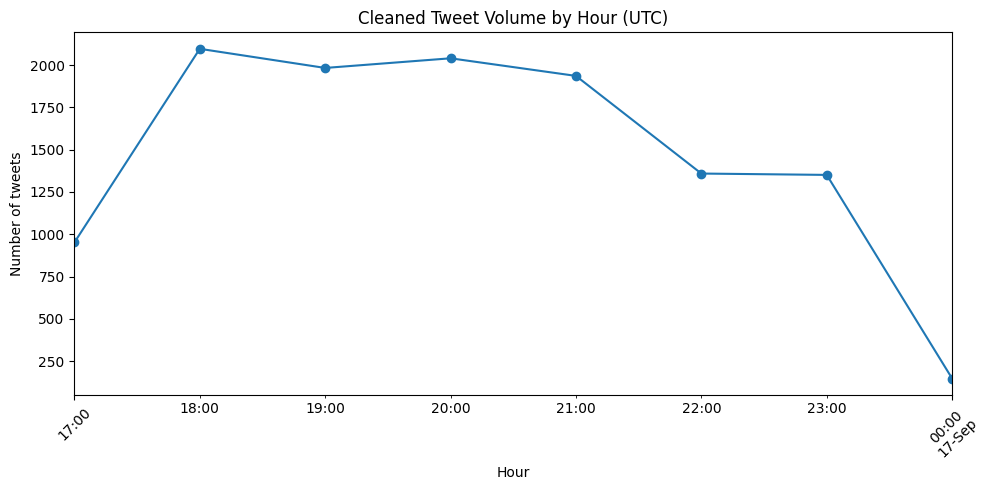

In [ ]:

#Plot Tweet Volume Over Time (Hourly Intervals)

model_data["hour"] = model_data["datetime"].dt.floor("h")
hour_counts = model_data.groupby("hour").size()

plt.figure(figsize=(10, 5))
hour_counts.plot(marker="o")
plt.title("Cleaned Tweet Volume by Hour (UTC)")
plt.xlabel("Hour")
plt.ylabel("Number of tweets")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


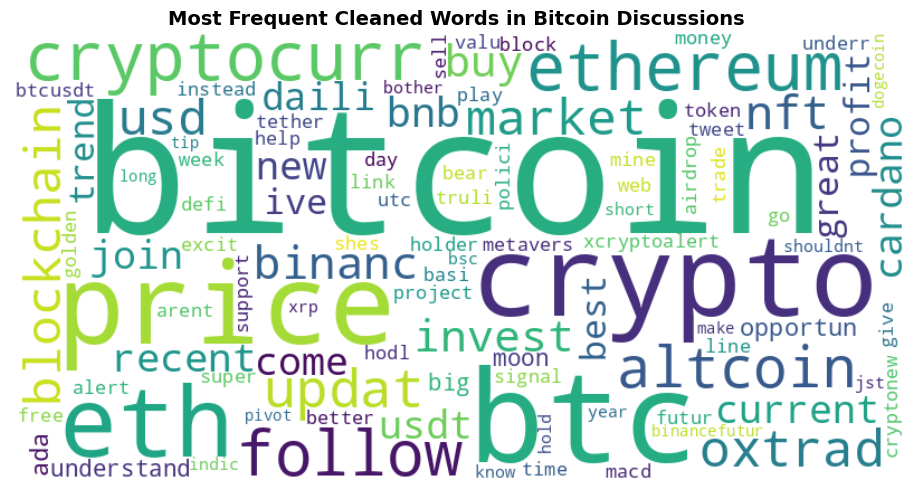

In [ ]:
#Word Cloud of Frequent Words

all_cleaned_text = " ".join(model_data["cleaned_text"])

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color="white",
    max_words=100,
    collocations=False
).generate(all_cleaned_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Most Frequent Cleaned Words in Bitcoin Discussions", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


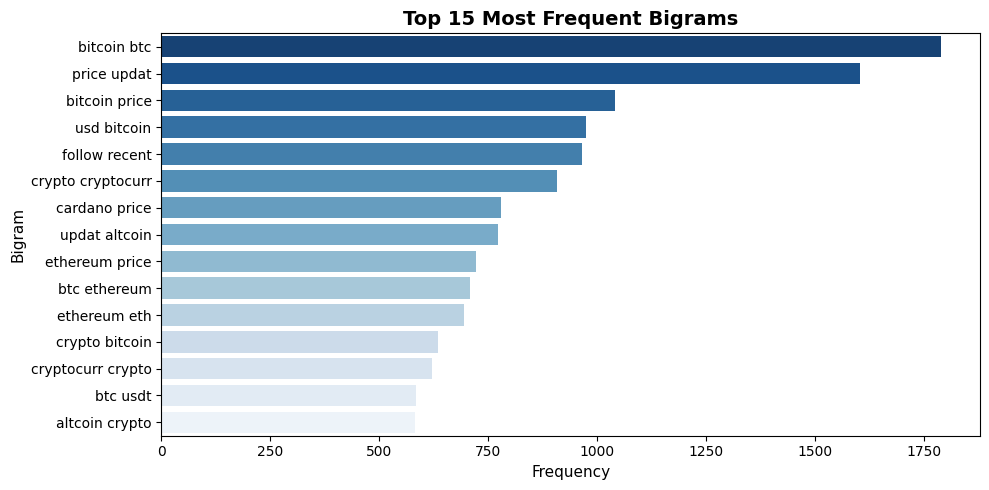

In [ ]:
#Bigrams Analysis & Visualisation

#Extract top bigrams using CountVectorizer
bigram_vec = CountVectorizer(ngram_range=(2, 2), max_features=15)
bigram_counts = bigram_vec.fit_transform(model_data["cleaned_text"])
bigram_sum = bigram_counts.sum(axis=0)

bigram_freq = [(word, bigram_sum[0, idx]) for word, idx in bigram_vec.vocabulary_.items()]
bigram_df = pd.DataFrame(sorted(bigram_freq, key=lambda x: x[1], reverse=True), columns=["Bigram", "Count"])

plt.figure(figsize=(10, 5))
sns.barplot(data=bigram_df, x="Count", y="Bigram", palette="Blues_r")
plt.title("Top 15 Most Frequent Bigrams", fontsize=14, fontweight='bold')
plt.xlabel("Frequency", fontsize=11)
plt.ylabel("Bigram", fontsize=11)
plt.tight_layout()
plt.show()

###Key Insights from the Bigrams



*   **price update / bitcoin price**: A significant fraction of the bigram frequencies are terms related to pricing structure. The fact that stemmed forms such as price update are present means that a considerable part of Twitter activity is made up of accounts run by bots, ticker services or news feeds that regularly report updates on the stock market. This implies that checking prices on a regular basis is the main reason for the overall high level of posts on the social media site.
*   **btc ethereum / update altcoin**: The phrases which correlate Bitcoin with other digital assets suggest that traders and the community at large consider the given cryptocurrency in relation to the market. In other words, they do not analyze it as an isolated asset but compare it with others (Ethereum or overall altcoins) in terms of prices, equity, or pairs.



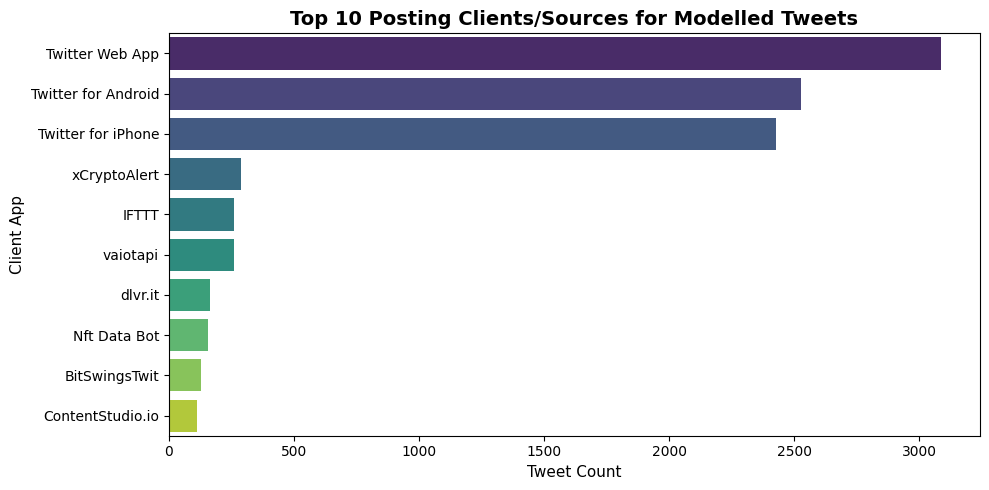

In [ ]:
#Additional Visualisation: Top 10 Tweet Sources / Clients

top_clients = model_data["Client"].value_counts().head(10).reset_index()
top_clients.columns = ["Client", "Count"]
#Strip quotes if present in client strings
top_clients["Client"] = top_clients["Client"].astype(str).str.replace('"', '')

plt.figure(figsize=(10, 5))
sns.barplot(data=top_clients, x="Count", y="Client", palette="viridis")
plt.title("Top 10 Posting Clients/Sources for Modelled Tweets", fontsize=14, fontweight='bold')
plt.xlabel("Tweet Count", fontsize=11)
plt.ylabel("Client App", fontsize=11)
plt.tight_layout()
plt.show()

#4. Text Representation

In [ ]:
#CountVectorizer Representation (Optimal for LDA)
count_vec = CountVectorizer(
    min_df=5,           # Ignore rare terms appearing in fewer than 5 tweets
    max_df=0.85,        # Ignore ultra-common terms appearing in >85% of documents
    ngram_range=(1, 2)  # Include single words and meaningful bigrams
)

tf_matrix = count_vec.fit_transform(model_data["cleaned_text"])

#Quick validation of shape/dimensions
print(f"Count Matrix Shape (LDA): {tf_matrix.shape}")

Count Matrix Shape (LDA): (11865, 6183)


In [ ]:
#TF-IDF Representation (Optimal NMF)
tfidf_vec = TfidfVectorizer(
    min_df=5,
    max_df=0.85,
    ngram_range=(1, 2)
)

tfidf_matrix = tfidf_vec.fit_transform(model_data["cleaned_text"])

print(f"TF-IDF Matrix Shape (NMF): {tfidf_matrix.shape}")

TF-IDF Matrix Shape (NMF): (11865, 6183)


  *   **CountVectorizer for LDA**: LDA is a probabilistic generative model that relies on discrete, integer-based word counts (frequencies) to model topics. Using raw term frequencies aligns with LDA's underlying statistical assumptions.
*   TF-IDF for NMF: NMF is a linear algebra factorization technique that works best with continuous, scaled feature matrices. TF-IDF weights down overly common words and highlights distinctive terms, making it ideal for matrix decomposition.





#5. Topic modelling and model comparison

In [ ]:
#LDA Topic Modelling using CountVectorizer

lda_models = {} #Dictionary to store LDA models for different topic numbers
for k in [4,5,6,7,8]: #Train LDA models for k = 4 to 8 topics
    lda = LatentDirichletAllocation(
        n_components=k,
        random_state=42,
        learning_method="batch"
    )
    lda.fit(tf_matrix) #Train LDA models for k = 4 to 8 topics - uses tf_matrix created in text representation
    lda_models[k] = lda
    print(f"\nLDA with k={k}")
    for idx, topic in enumerate(lda.components_):
        top_words = [count_vec.get_feature_names_out()[i] for i in topic.argsort()[:-11:-1]]
        print(f"Topic {idx}: ", " ".join(top_words))


LDA with k=4
Topic 0:  crypto btc cryptocurr blockchain ethereum crypto bitcoin market binanc follow invest
Topic 1:  btc eth ethereum crypto project price nft cryptocurr bnb defi
Topic 2:  price follow bitcoin price ive btc line macd underr buy great
Topic 3:  btc price updat altcoin price updat eth oxtrad usd bitcoin btc crypto

LDA with k=5
Topic 0:  crypto btc cryptocurr blockchain crypto bitcoin ethereum market invest binanc cryptonew
Topic 1:  eth btc ethereum project crypto price nft pivot bnb support
Topic 2:  price bitcoin price line macd follow btc understand opportun great buy
Topic 3:  btc price updat eth price updat crypto bitcoin btc cryptocurr usd ethereum
Topic 4:  oxtrad altcoin come big blockchain join profit market invest holder

LDA with k=6
Topic 0:  crypto btc cryptocurr blockchain crypto bitcoin ethereum binanc invest cryptonew market
Topic 1:  btc project ethereum eth crypto nft buy airdrop cryptocurr binanc
Topic 2:  price btc eth crypto nft arent news bitcoin

In [ ]:
#NMF Topic Modelling using TF-IDF

nmf_models = {}

# Train NMF models for k = 4 to 8 topics
for k in [4,5,6,7,8]:
    nmf_model = NMF(n_components=k, random_state=42)
    nmf_model.fit(tfidf_matrix)
    nmf_models[k] = nmf_model

    print(f"\nNMF with k={k}")
    for topic_idx, topic in enumerate(nmf_model.components_):
        top_words = [tfidf_vec.get_feature_names_out()[i]
                     for i in topic.argsort()[-10:][::-1]]
        print(f"Topic {topic_idx}: " + " ".join(top_words))


NMF with k=4
Topic 0: price price updat updat eth follow recent usd bitcoin recent cardano price usd cardano
Topic 1: oxtrad invest holder polici moon holder big trend market basi trend give invest big profit best polici market best
Topic 2: ive understand bitcoin golden opportun underr bitcoin super underr bitcoin ive instead excit price shouldnt shouldnt bother bother instead
Topic 3: xcryptoalert btc usdt usdt btc binanc futur jst btc xcryptoalert btc xcryptoalert xcryptoalert tether binanc futur binancefutur

NMF with k=5
Topic 0: price updat updat price eth updat eth recent eth eth price eth usd altcoin cryptocurr btc follow
Topic 1: oxtrad holder big give invest polici moon invest holder trend market big profit best polici basi trend market best
Topic 2: ive understand bitcoin golden opportun underr bitcoin super underr bitcoin ive bother instead instead excit excit golden price shouldnt
Topic 3: xcryptoalert btc usdt usdt btc binanc futur xcryptoalert xcryptoalert binancefutur 

In [ ]:
#Coherence Scores for LDA

#Create dictionary from cleaned corpus
texts = [t.split() for t in model_data["cleaned_text"]]
dictionary = corpora.Dictionary(texts)

lda_coherence_scores = {}
for k, model in lda_models.items():
    topics = []
    for topic in model.components_:
        # Extract top 10 words per topic
        top_words = [count_vec.get_feature_names_out()[i]
                     for i in topic.argsort()[-10:][::-1]]
        topics.append(top_words)

    coherence_model = CoherenceModel(
        topics=topics,
        texts=texts,
        dictionary=dictionary,
        coherence='c_v'
    )
    lda_coherence_scores[k] = coherence_model.get_coherence()

print("LDA Coherence Scores")
for k, score in lda_coherence_scores.items():
    print(f"k={k}: {score:.4f}")

LDA Coherence Scores
k=4: 0.5623
k=5: 0.6914
k=6: 0.6559
k=7: 0.6773
k=8: 0.6792


In [ ]:
#Coherence Scores for NMF
nmf_coherence_scores = {}
for k, model in nmf_models.items():
    topics = []
    for topic in model.components_:
        #Extract top 10 words per topic
        top_words = [tfidf_vec.get_feature_names_out()[i]
                     for i in topic.argsort()[-10:][::-1]]
        topics.append(top_words)

    coherence_model = CoherenceModel(
        topics=topics,
        texts=texts,
        dictionary=dictionary,
        coherence='c_v'
    )
    nmf_coherence_scores[k] = coherence_model.get_coherence()

print("NMF Coherence Scores")
for k, score in nmf_coherence_scores.items():
    print(f"k={k}: {score:.4f}")

NMF Coherence Scores
k=4: 0.9582
k=5: 0.9554
k=6: 0.9302
k=7: 0.9442
k=8: 0.9386


In [ ]:
#Topic Diversity for LDA and NMF

#Function to calculate diversity: proportion of unique words across all topics
def topic_diversity(topics):
    all_words = []
    for topic in topics:
        all_words.extend(topic)
    unique_words = set(all_words)
    return len(unique_words) / len(all_words)

    #LDA Diversity
print("LDA Topic Diversity")
for k, model in lda_models.items():
    topics = [[count_vec.get_feature_names_out()[i]
               for i in topic.argsort()[-10:][::-1]]
              for topic in model.components_]
    diversity_score = topic_diversity(topics)
    print(f"k={k}: Diversity = {diversity_score:.4f}")

#NMF Diversity
print("\nNMF Topic Diversity")
for k, model in nmf_models.items():
    topics = [[tfidf_vec.get_feature_names_out()[i]
               for i in topic.argsort()[-10:][::-1]]
              for topic in model.components_]
    diversity_score = topic_diversity(topics)
    print(f"k={k}: Diversity = {diversity_score:.4f}")

LDA Topic Diversity
k=4: Diversity = 0.7250
k=5: Diversity = 0.7200
k=6: Diversity = 0.6667
k=7: Diversity = 0.6286
k=8: Diversity = 0.6500

NMF Topic Diversity
k=4: Diversity = 1.0000
k=5: Diversity = 0.9800
k=6: Diversity = 0.9500
k=7: Diversity = 0.9571
k=8: Diversity = 0.9375


In [ ]:
#Human Interpretability: Inspect Top Words per Topic

# LDA Top Words
print("LDA Top Words (Human Interpretability)")
for k, model in lda_models.items():
    print(f"\nLDA with k={k}")
    for topic_idx, topic in enumerate(model.components_):
        #Extract top 10 words for each topic
        top_words = [count_vec.get_feature_names_out()[i]
                     for i in topic.argsort()[-10:][::-1]]
        print(f"Topic {topic_idx}: " + " ".join(top_words))

#NMF Top Words
print("\nNMF Top Words (Human Interpretability)")
for k, model in nmf_models.items():
    print(f"\nNMF with k={k}")
    for topic_idx, topic in enumerate(model.components_):
        #Extract top 10 words for each topic
        top_words = [tfidf_vec.get_feature_names_out()[i]
                     for i in topic.argsort()[-10:][::-1]]
        print(f"Topic {topic_idx}: " + " ".join(top_words))

LDA Top Words (Human Interpretability)

LDA with k=4
Topic 0: crypto btc cryptocurr blockchain ethereum crypto bitcoin market binanc follow invest
Topic 1: btc eth ethereum crypto project price nft cryptocurr bnb defi
Topic 2: price follow bitcoin price ive btc line macd underr buy great
Topic 3: btc price updat altcoin price updat eth oxtrad usd bitcoin btc crypto

LDA with k=5
Topic 0: crypto btc cryptocurr blockchain crypto bitcoin ethereum market invest binanc cryptonew
Topic 1: eth btc ethereum project crypto price nft pivot bnb support
Topic 2: price bitcoin price line macd follow btc understand opportun great buy
Topic 3: btc price updat eth price updat crypto bitcoin btc cryptocurr usd ethereum
Topic 4: oxtrad altcoin come big blockchain join profit market invest holder

LDA with k=6
Topic 0: crypto btc cryptocurr blockchain crypto bitcoin ethereum binanc invest cryptonew market
Topic 1: btc project ethereum eth crypto nft buy airdrop cryptocurr binanc
Topic 2: price btc eth cr

In [ ]:
#NMF Stability Check for Best k

#Select the best topic number (k) based on coherence results
#Replace this with your chosen k after reviewing scores
best_k = max(nmf_coherence_scores, key=nmf_coherence_scores.get)

#Re-run NMF with a different random seed
nmf_model_stable = NMF(n_components=best_k, random_state=7)
nmf_model_stable.fit(tfidf_matrix)

#Print top words for each topic in the stable run
print(f"\nStable run comparison for NMF (k={best_k}, random_state=7):")
for idx, topic in enumerate(nmf_model_stable.components_):
    top_words = [tfidf_vec.get_feature_names_out()[i]
                 for i in topic.argsort()[-10:][::-1]]
    print(f"Topic {idx}: " + " ".join(top_words))


Stable run comparison for NMF (k=4, random_state=7):
Topic 0: price price updat updat eth follow recent usd bitcoin recent cardano price usd cardano
Topic 1: oxtrad invest holder polici moon holder big trend market basi trend give invest big profit best polici market best
Topic 2: ive understand bitcoin golden opportun underr bitcoin super underr bitcoin ive instead excit price shouldnt shouldnt bother bother instead
Topic 3: xcryptoalert btc usdt usdt btc binanc futur jst btc xcryptoalert btc xcryptoalert xcryptoalert tether binanc futur binancefutur


Re‑running NMF with random_state=7 produced similar themes to the original run. While some individual words shifted (e.g. ‘update’ replaced by ‘news’), the overall topics — cryptocurrency trading, market updates and investor sentiment remained consistent. This demonstrates that the chosen topic number is reasonably stable.

#6. Topic Analysis

In [ ]:
#Important Keywords + Example Tweets

#Select the best topic number (k)
best_k = max(nmf_coherence_scores, key=nmf_coherence_scores.get)

#Load the chosen model
nmf_model = nmf_models[best_k]

#Show 10 keywords + 2 example tweets per topic
print(f"NMF Topics (k={best_k})")
for idx, topic in enumerate(nmf_model.components_):
    #Extract top 10 keywords
    keywords = [tfidf_vec.get_feature_names_out()[i]
                for i in topic.argsort()[-10:][::-1]]
    print(f"\nTopic {idx} Keywords: {', '.join(keywords)}")

    #Find 2 example tweets strongly associated with this topic
    topic_tweets = []
    for i, row in enumerate(tfidf_matrix):
        topic_probs = nmf_model.transform(tfidf_matrix[i])
        dominant_topic = topic_probs.argmax()
        if dominant_topic == idx:
            topic_tweets.append(model_data.iloc[i]["cleaned_text"])
        if len(topic_tweets) >= 2:
            break

    print("Example Tweets:")
    for t in topic_tweets:
        print("-", t)

NMF Topics (k=4)

Topic 0 Keywords: price, price updat, updat, eth, follow recent, usd bitcoin, recent, cardano price, usd, cardano
Example Tweets:
- bitcoin price just went current price bitcoin btc crypto nft news blockchain web eth
- saitama saitamawolfpack saitapro saita crypto cryptocurr cryptonew ethereum bitcoin eth btc saitamatoken luna invest invest saitarealti saitamacommun saitamallc metavers wearesaitama usesaitapro wolfpack

Topic 1 Keywords: oxtrad, invest holder, polici moon, holder big, trend market, basi trend, give invest, big profit, best polici, market best
Example Tweets:
- ad polit info candid stanc bitcoin fantast major polit topic come year dollar global economi crash harder
- hey join network call surveyj earn today paid test new free app post social media sign link instant signup bonus surveyj cashapp bitcoin

Topic 2 Keywords: ive, understand bitcoin, golden opportun, underr bitcoin, super underr, bitcoin ive, instead excit, price shouldnt, shouldnt bother, b

Share of Tweets per Topic (%)
Topic
0    39.151965
3    30.052615
2    17.332095
1    13.463324
Name: proportion, dtype: float64


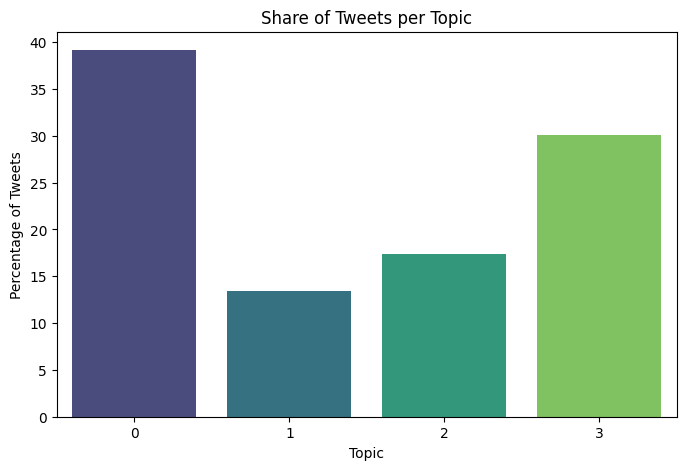

In [ ]:
#Assign Each Tweet to Dominant Topic

#Choose final model (NMF with best_k)

best_k = max(nmf_coherence_scores, key=nmf_coherence_scores.get)

nmf_model = nmf_models[best_k]

#Assign each tweet to its dominant topic

topic_assignments = []

for i in range(tfidf_matrix.shape[0]):

    topic_probs = nmf_model.transform(tfidf_matrix[i])

    dominant_topic = topic_probs.argmax()

    prob = topic_probs[0, dominant_topic]

    topic_assignments.append((i, dominant_topic, prob))

#Convert to DataFrame

topic_df = pd.DataFrame(
    topic_assignments,
    columns=["TweetIndex", "Topic", "Probability"]
)

#Merge with original tweets (and datetime if available)

topic_df = topic_df.merge(
    model_data[["cleaned_text", "datetime"]].reset_index(),
    left_on="TweetIndex",
    right_on="index"
)

#Calculate share of tweets per topic

share_table = topic_df["Topic"].value_counts(normalize=True) * 100

print("Share of Tweets per Topic (%)")

print(share_table)

#Visualise share of tweets

plt.figure(figsize=(8,5))

sns.barplot(
    x=share_table.index,
    y=share_table.values,
    palette="viridis"
)

plt.title("Share of Tweets per Topic")

plt.xlabel("Topic")

plt.ylabel("Percentage of Tweets")

plt.show()

In [ ]:
# Create the final dataset for the assignment

topic_assignments_export = topic_df[
    ["TweetIndex", "Topic", "Probability", "cleaned_text", "datetime"]
].copy()

# Add the original Tweet Id using the TweetIndex
topic_assignments_export["Tweet Id"] = model_data.iloc[
    topic_assignments_export["TweetIndex"]
]["Tweet Id"].values

# Rename columns
topic_assignments_export = topic_assignments_export.rename(
    columns={
        "Topic": "assigned_topic",
        "Probability": "topic_probability"
    }
)

# Keep only the required columns
topic_assignments_export = topic_assignments_export[
    [
        "Tweet Id",
        "datetime",
        "cleaned_text",
        "assigned_topic",
        "topic_probability"
    ]
]

# Check the final dataset
print("Rows:", len(topic_assignments_export))
print("Columns:", topic_assignments_export.columns.tolist())

topic_assignments_export.head()

Rows: 3231
Columns: ['Tweet Id', 'datetime', 'cleaned_text', 'assigned_topic', 'topic_probability']


,Tweet Id,datetime,cleaned_text,assigned_topic,topic_probability
0,"""1570926632327876609""",2022-09-17 00:04:48,bitcoin price just went current price bitcoin ...,3,0.000039
1,"""1570926606822309891""",2022-09-17 00:04:46,saitama saitamawolfpack saitapro saita crypto ...,2,0.011590
2,"""1570926603651411968""",2022-09-17 00:04:46,lol sharp,3,0.004914
3,"""1570926537792425987""",2022-09-17 00:04:42,check tonight btc bitcoin crypto cryptocurr tr...,3,0.003063
4,"""1570926460671516675""",2022-09-17 00:04:30,bitcoin fix,0,0.027371


In [ ]:
#Verify the required columns

print(topic_assignments_export.columns.tolist())

print("\nMissing values:")
print(topic_assignments_export.isnull().sum())

print("\nFirst 5 rows:")
display(topic_assignments_export.head())

['Tweet Id', 'datetime', 'cleaned_text', 'assigned_topic', 'topic_probability']

Missing values:
Tweet Id             0
datetime             0
cleaned_text         0
assigned_topic       0
topic_probability    0
dtype: int64

First 5 rows:


,Tweet Id,datetime,cleaned_text,assigned_topic,topic_probability
0,"""1570926632327876609""",2022-09-17 00:04:48,bitcoin price just went current price bitcoin ...,3,0.000039
1,"""1570926606822309891""",2022-09-17 00:04:46,saitama saitamawolfpack saitapro saita crypto ...,2,0.011590
2,"""1570926603651411968""",2022-09-17 00:04:46,lol sharp,3,0.004914
3,"""1570926537792425987""",2022-09-17 00:04:42,check tonight btc bitcoin crypto cryptocurr tr...,3,0.003063
4,"""1570926460671516675""",2022-09-17 00:04:30,bitcoin fix,0,0.027371


In [ ]:
#Export the dataset to CSV

topic_assignments_export.to_csv(
    "topic_assignments.csv",
    index=False
)

print("topic_assignments.csv has been created successfully.")

topic_assignments.csv has been created successfully.


In [ ]:
from google.colab import files

files.download("topic_assignments.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

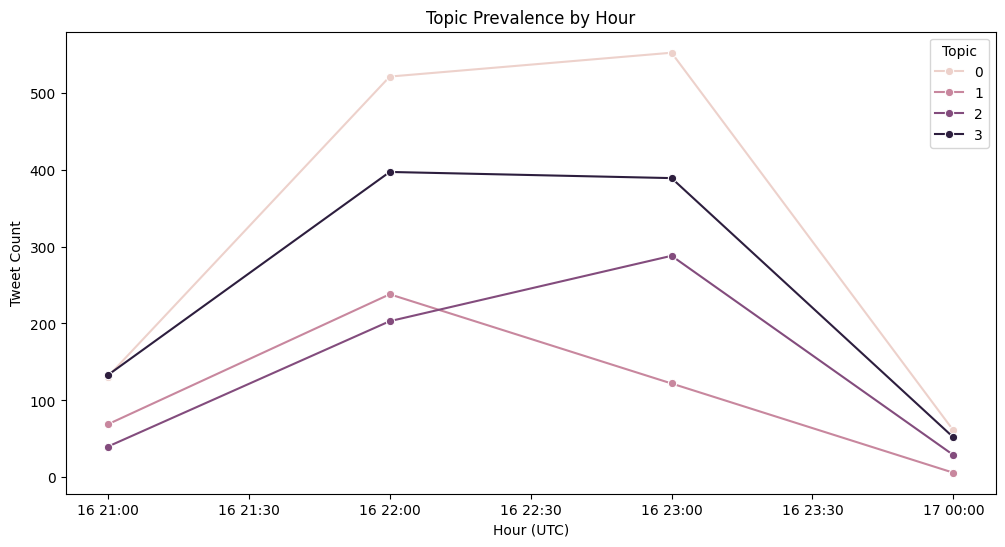

In [ ]:
#Topic Prevalence by Hour

#Assign each tweet to its dominant topic
topic_assignments = []
for i in range(tfidf_matrix.shape[0]):
    topic_probs = nmf_model.transform(tfidf_matrix[i])
    dominant_topic = topic_probs.argmax()
    topic_assignments.append((i, dominant_topic))

#Build DataFrame with datetime
topic_df = pd.DataFrame(topic_assignments, columns=["TweetIndex", "Topic"])
topic_df = topic_df.merge(model_data[["datetime"]].reset_index(),
                          left_on="TweetIndex", right_on="index")

#Group by hour and topic
topic_df["hour"] = topic_df["datetime"].dt.floor("h")
topic_counts = topic_df.groupby(["hour", "Topic"]).size().reset_index(name="Count")

#Plot topic prevalence by hour
plt.figure(figsize=(12,6))
sns.lineplot(data=topic_counts, x="hour", y="Count", hue="Topic", marker="o")
plt.title("Topic Prevalence by Hour")
plt.xlabel("Hour (UTC)")
plt.ylabel("Tweet Count")
plt.legend(title="Topic")
plt.show()

###Insight 1: Price Alerts Dominate

The model shows that opics with keywords like price, update, eth, usd, cardano had the highest prevalence during certain hours, especially overlapping with market activity. This suggests that Twitter users react strongly to live price movements. Social media acts as a real‑time reflection of investor psychology, amplifying trading sentiment during market‑open hours.

###Insight 2: Investment trends are steady

The model shows that a topic with words such as oxtrad, invest, holder, profit, policy, market appeared consistently across the dataset, with relatively stable prevalence over time. This means that investment trend discussions are structural and ongoing, not tied to sudden events. This indicates a persistent community focus on trading strategies and long‑term profitability.

###Insight 3: Bitcoin Opportunuties rise in the evenings

 The model shows that topics including golden opportunity, super undervalued, bitcoin, excitement increased in prevalence later in the day. This may reflect global overlap in trading hours or community hype cycles. It highlights how Bitcoin is often contextualized as an opportunity narrative, especially during periods of heightened market attention.

###Insight 4: Exchange Alerts Spike Irregularly

The model showed that topics with words like xcryptoalert, USDT, Binance, tether, futures showed irregular spikes rather than steady patterns. These bursts likely correspond to automated alerts or sudden exchange announcements. They demonstrate how external triggers (bots, trading platforms, news services) can temporarily dominate Bitcoin discussions.